# Milestone 3 - Moteur d'optimisation des livraisons

## 0. Résumé

**Problème :** aujourd'hui, chaque besoin est livré le jour même. Cela fait 1 665 livraisons en 6 semaines, avec des camions remplis à 1,6 % en médiane. **Objectif :** pour chaque couple fournisseur × usine, choisir des **jours de livraison fixes** (le profil), y regrouper les besoins avec au plus 7 jours d'avance, et **minimiser le coût de transport**, sans saturer les quais des usines.

**Résultats** (dernière exécution ; les chiffres peuvent varier d'environ 0,1 % d'une exécution à l'autre, à cause des limites de temps du solveur) :

| Indicateur | Actuel | Plan final | Écart |
| :--- | ---: | ---: | ---: |
| Coût de transport | 176 725 € | **110 330 €** | **−37,6 %** |
| Livraisons | 1 665 | 654 | −61 % |
| Camions | 1 741 | 761 | −56 % |
| Pic de camions reçus sur un jour (PLT_002) | 54 | 19 | −65 % |

- **Profils serrés :** 131 couples livrés 1 fois par semaine, 45 deux fois, 4 trois fois. Aujourd'hui, 31 couples sont livrés jusqu'à 5 fois par semaine.
- **Lissage :** sans lissage, l'optimisation concentre les livraisons sur quelques jours (56 camions sur un jour à PLT_002). La deuxième passe répartit la charge sur la semaine, pour +0,6 % de coût.
- **Lignes entières :** chaque ligne part entière dans un seul camion, et chaque camion est facturé sur son propre poids. La situation actuelle est rechargée de la même façon : les deux plans sont comparés à méthode égale.
- **À trancher avec le client :** la règle de choix du profil (RG07, `profile_tolerance`) et le surcoût accepté pour le lissage (RG09, `smoothing_tolerance`).

**Entrées :** `data/consolidated_dataset.csv` (Milestone 1 : besoins nettoyés, avec distance), `docs/rate_sheet.csv` (grille tarifaire), `data/baseline_deliveries.csv` (Milestone 2 : situation actuelle).

**Plan du notebook :** 1. Modèles · 2. Paramètres et données · 3. Préparation du moteur · 4. Validation · 5. Passe 1 : optimisation · 6. Passe 2 : lissage · 7. Plan final et contrôles · 8. Sortie 1 : profils · 9. Sortie 2 : articles par camion · 10. Sortie 3 : saving · 11. Export · Annexes.

Le temps d'exécution de chaque étape est en annexe A.3. Le fonctionnement détaillé du moteur, avec le lien entre chaque formule et le code, est dans [engine.md](engine.md).

## 1. Modèles

Le moteur enchaîne **trois modèles d'optimisation**. Le premier choisit les jours, le deuxième remplit les camions, le troisième répartit la charge des usines :

```
besoins ─► 1.1 Passe 1 (un problème par couple × profil N) ─► profil de chaque couple (section 5)
                                                                    │
     1.1 avec jours imposés + 1.2 chargement = options de jours ◄───┘
                                                                    │
                                     1.3 Lissage (un problème par usine) ─► jours finaux de chaque couple
                                                                    │
                                     1.2 Chargement (une livraison à la fois) ─► camions et coût publié
```

### 1.1 Passe 1 : jours de livraison et profil d'un couple

| | |
| :--- | :--- |
| **Entrées** | pour **un couple** $c$ : ses lignes de besoin (jour de besoin $i_l$, poids $W_l$, volume $V_l$) ; le prix d'un camion dans chaque tranche $p_{c,k}$ et les bornes des tranches $\bar w_k$ ; le calendrier des jours de livraison $J$ ; le profil testé $N$ ; la fenêtre d'anticipation (7 jours) ; en option, des jours de semaine imposés (utilisé par le lissage) |
| **Sorties** | le **jour de livraison de chaque ligne** ; les **jours de semaine autorisés**, dont le nombre est le profil ; le coût estimé par le modèle (capacité vérifiée sur le total du jour) ; le statut du solveur |
| **Code** | `solve_couple` → `CoupleSolution` ; `solve_all` lance les 180 couples × 5 profils en parallèle |

#### Ensembles

| Symbole | Signification | Règle |
| :--- | :--- | :--- |
| $C$ | couples $c = (f, u)$ fournisseur × usine ayant au moins un besoin (180) | RG01 |
| $L_c$ | lignes de besoin du couple $c$ : un matériau $m$, un quai, un jour de besoin $i_l$ | |
| $J$ | jours de livraison possibles : jours ouvrés hors fériés allemands, du premier besoin − 7 jours au dernier besoin | RG10 |
| $A_l \subseteq J$ | jours où la ligne $l$ peut arriver : $i_l - 7 \le j \le i_l$ (jours calendaires) | RG03 |
| $D$ | jours de la semaine (lundi … vendredi) ; $wd(j)$ = jour de la semaine de $j$ | RG05 |
| $K$ | tranches de poids de la grille (≤ 50 kg, …, ≤ 4 000 kg, > 4 000 kg) | RG11 |

#### Paramètres

| Symbole | Signification |
| :--- | :--- |
| $W_l$, $V_l$ | poids (kg) et volume (m³) de la ligne $l$ |
| $d_c$ | distance du fournisseur du couple $c$ (km) |
| $\bar w_k$ | borne haute de la tranche $k$ ; la dernière (> 4 000 kg) est bornée par la capacité $Q$ |
| $p_{c,k}$ | prix d'un camion du couple $c$ dans la tranche $k$ : $\text{base}(d_c, k) \times (1 + \text{marge}) \times \text{diesel}$ |
| $p^{\max}_c$ | prix d'un camion plein au **tarif forfaitaire** : $p^{\max}_c = p_{c,\bar k}$, où $\bar k$ est la dernière tranche de la grille (> 4 000 kg) ; le prix y est le même quel que soit le poids, jusqu'à $Q$ |
| $Q$, $\bar V$ | capacité d'un camion : 24 500 kg et 110,4 m³ (RG04) |
| $N$ | profil testé : au plus $N$ jours de livraison par semaine (1 à 5) |
| $\varepsilon$ | petite pénalité par jour de livraison (0,01 €) : à coût égal, on préfère moins de livraisons |

#### Variables (toutes indexées par le couple $c$)

| Variable | Signification |
| :--- | :--- |
| $z_{c,l,j} \in \{0,1\}$ | la ligne $l$ du couple $c$ est livrée le jour $j \in A_l$ |
| $x_{c,j} \in \{0,1\}$ | le couple $c$ est livré le jour $j$ (une livraison = un couple × un jour, RG12) |
| $F_{c,j} \in \mathbb{N}$ | camions **pleins** du couple $c$ le jour $j$, facturés au forfait et comptés pour une capacité entière |
| $y_{c,j,k} \in \{0,1\}$ | le **dernier camion** du couple $c$ le jour $j$ est dans la tranche $k$ |
| $s_{c,d} \in \{0,1\}$ | le jour de semaine $d$ est un **jour autorisé** du couple $c$ (livraison possible ce jour-là, sans obligation) |
| $h_{c,w} \in \{0,1\}$ | la semaine $w$ est une semaine où **tous** les jours autorisés du couple $c$ sont livrés |

#### Objectif

$$\min \; \sum_{c \in C} \sum_{j \in J} \Big( p^{\max}_c \, F_{c,j} + \sum_{k \in K} p_{c,k} \, y_{c,j,k} + \varepsilon \, x_{c,j} \Big)$$

#### Contraintes (pour tout couple $c \in C$)

| N° | Contrainte | Sens | Règle |
| :--- | :--- | :--- | :--- |
| (1) | $\sum_{j \in A_l} z_{c,l,j} = 1 \quad \forall l \in L_c$ | chaque ligne est livrée une fois, dans sa fenêtre | RG03, RG08 |
| (2) | $z_{c,l,j} \le x_{c,j}$ | pas de ligne livrée un jour sans livraison | RG12 |
| (3) | $\sum_{l} W_l \, z_{c,l,j} \le Q \, F_{c,j} + \sum_k \bar w_k \, y_{c,j,k} \quad \forall j$ | le poids du jour tient dans les camions payés | RG04, RG11 |
| (4) | $\sum_{l} V_l \, z_{c,l,j} \le \bar V \, \big(F_{c,j} + \sum_k y_{c,j,k}\big) \quad \forall j$ | le volume du jour tient dans les camions | RG04 |
| (5) | $\sum_k y_{c,j,k} = x_{c,j} \quad \forall j$ | une livraison a exactement un « dernier camion » | |
| (6) | $F_{c,j} \le M_{c,j} \, x_{c,j}$, $\;x_{c,j} \le \sum_l z_{c,l,j} \quad \forall j$ | pas de camion sans livraison ($M_{c,j}$ = lignes possibles ce jour), pas de livraison vide | |
| (7) | $x_{c,j} \le s_{c,\,wd(j)} \quad \forall j$, $\;\sum_{d \in D} s_{c,d} \le N$ | au plus $N$ jours autorisés ; on ne livre qu'un jour autorisé, mais une semaine peut sauter un jour autorisé | RG05 |
| (8) | $x_{c,j} \ge s_{c,\,wd(j)} + h_{c,w(j)} - 1 \quad \forall j$, $\;\sum_{w} h_{c,w} \ge 1$ | le profil est **atteint** : au moins une semaine livre tous les jours autorisés, donc la fréquence max réelle = nombre de jours autorisés | RG05 |

### 1.2 Chargement : les lignes entières d'une livraison dans des camions

| | |
| :--- | :--- |
| **Entrées** | **une livraison** (un couple × un jour), fixée par la passe 1 ou le lissage : le poids $W_l$ et le volume $V_l$ de chacune de ses lignes ; le prix d'un camion dans chaque tranche $p_k$ du couple et les bornes $\bar w_k$ ; la capacité d'un camion $Q$, $\bar V$ |
| **Sorties** | le **numéro de camion de chaque ligne** ; le poids, le volume et le **coût de chaque camion**, facturé sur son propre poids ; le nombre de camions |
| **Code** | `load_delivery` → `DeliveryLoad` (une livraison) ; `load_plan` dans ce notebook (toutes les livraisons d'un plan) |

Une ligne n'est **jamais coupée** : son volume n'est pas divisible. Une livraison qui tient dans un camion part dans **un seul camion**, sans calcul (plus de 90 % des cas). Sinon :

| Élément | Formulation, pour une livraison |
| :--- | :--- |
| Variables | $a_{l,b} \in \{0,1\}$ : la ligne $l$ est dans le camion $b$ ; $t_b \in \{0,1\}$ : le camion $b$ part ; $y_{b,k} \in \{0,1\}$ : le camion $b$ est facturé dans la tranche $k$ |
| Une ligne, un camion | $\sum_b a_{l,b} = 1$ |
| Poids | $\sum_l W_l \, a_{l,b} \le \sum_k \bar w_k \, y_{b,k}$, avec $\sum_k y_{b,k} = t_b$ (la dernière tranche est bornée par 24 500 kg) |
| Volume | $\sum_l V_l \, a_{l,b} \le \bar V \, t_b$ |
| Objectif | **d'abord le moins de camions**, puis le coût le plus bas : $\min \; P \sum_b t_b + \sum_{b,k} p_k \, y_{b,k}$, avec $P$ plus grand que toute différence de prix |

- **Pourquoi d'abord le nombre de camions :** la grille n'est pas sous-additive. Par exemple, 1 050 kg dans un camion coûtent plus que deux camions de 1 000 kg et 50 kg. Un minimum de coût pur enverrait des camions en plus pour profiter des bords de tranche, ce qui n'a pas de sens sur le terrain.
- **Le coût publié vient toujours de ce chargement**, pour le plan optimisé comme pour la situation actuelle. L'estimateur du Milestone 2, qui traitait la charge comme divisible, n'est gardé que pour mesurer son biais (annexe A.1).

### 1.3 Passe 2 : lissage de la charge d'une usine (RG09)

| | |
| :--- | :--- |
| **Entrées** | pour **une usine** $u$ et chacun de ses couples $c$ : son profil $N_c$ (fixé par la passe 1) ; toutes ses **options** de jours, c'est-à-dire chaque jeu de $N_c$ jours de la semaine, avec son coût chargé $\kappa_{c,o}$ et ses camions par jour $\tau_{c,o,j}$ (obtenus par le modèle 1.1 avec jours imposés, puis le chargement 1.2) ; l'option retenue par la passe 1 ; le surcoût accepté $\text{tol}$ |
| **Sorties** | **un jeu de jours par couple**, donc le plan final de chaque couple ; le pic de camions de l'usine avant et après ; le coût avant et après |
| **Code** | `build_options` (les options de tous les couples, en parallèle) puis `smooth_plant` → `PlantSmoothing` (une usine) |

| Symbole | Signification |
| :--- | :--- |
| $C_u$ | couples de l'usine $u$ |
| $O_c$ | jeux de jours possibles du couple $c$ : toutes les combinaisons de $N_c$ jours de la semaine (5 options pour $N_c = 1$, 10 pour $N_c = 2$ ou 3) |
| $o^1_c \in O_c$ | jeu de jours retenu par la passe 1 |
| $\kappa_{c,o}$ | coût du couple $c$ avec le jeu $o$, chargé camion par camion |
| $\tau_{c,o,j}$ | nombre de camions du couple $c$ le jour $j$ avec le jeu $o$ |
| $\text{tol}$ | surcoût accepté pour l'usine (`smoothing_tolerance`, 1 %) |
| $u_{c,o} \in \{0,1\}$ | variable : le couple $c$ reçoit le jeu de jours $o$ |
| $P_u \ge 0$ | variable : pic de l'usine, camions reçus le jour le plus chargé |

Pour chaque usine $u$, en deux temps :

| Étape | Problème |
| :--- | :--- |
| 1. pic minimal | $\min P_u$ sous $\sum_{o \in O_c} u_{c,o} = 1 \;\; \forall c \in C_u$, $\;\sum_{c \in C_u} \sum_{o} \tau_{c,o,j} \, u_{c,o} \le P_u \;\; \forall j$, $\;\sum_{c \in C_u} \sum_{o} \kappa_{c,o} \, u_{c,o} \le (1 + \text{tol}) \sum_{c \in C_u} \kappa_{c,o^1_c}$ |
| 2. coût minimal | mêmes contraintes, avec le pic fixé à la valeur $P_u^*$ de l'étape 1 : $\min \sum_{c \in C_u} \sum_{o} \kappa_{c,o} \, u_{c,o}$ |

### 1.4 Lecture des modèles

- **Coût (3) et (5) :** des camions pleins au forfait, puis un dernier camion facturé selon sa tranche de poids. Le solveur choisit la tranche la moins chère qui couvre le reste : il n'y a pas besoin d'imposer de borne basse.
- **Lignes et non jours de besoin (1) :** deux matériaux d'un même jour de besoin peuvent arriver des jours différents.
- **La passe 1 choisit les jours, le chargement remplit les camions :** dans (3) et (4), la capacité est vérifiée sur le total du jour, comme si une ligne pouvait se répartir entre deux camions. C'est exact pour une livraison qui tient dans un camion, c'est-à-dire la grande majorité. Le chargement (1.2) range ensuite les lignes **entières** et donne le vrai nombre de camions et le vrai coût.
- **Décomposition :** aucune contrainte de la passe 1 ne relie deux couples. Le problème global est la somme de 180 petits problèmes. Chaque couple × profil $N$ (900 problèmes) est résolu **en parallèle** sur tous les cœurs du processeur, avec une limite de temps par problème : le calcul complet (deux passes) prend environ trois minutes.
- **Profil (7) et (8) :** le profil, c'est une **fréquence max par semaine avec des jours autorisés**. Par exemple, « 2 par semaine, lundi et jeudi » : une semaine où il n'y a qu'une livraison, elle a lieu le lundi ou le jeudi. Le nombre de jours autorisés est égal à la fréquence max.
- **Pourquoi (8) :** sans elle, un couple livré une seule fois par semaine pourrait garder les 5 jours autorisés pour choisir chaque semaine le jour le moins cher. Il afficherait alors un profil 5 et ferait provisionner des créneaux de réception qui ne servent jamais. Avec (8), chaque jour autorisé est utilisé au moins une même semaine. Seules les semaines complètes de l'horizon peuvent servir de semaine de référence, et un jour férié est ignoré.
- **Choix du profil :** le coût **baisse** quand $N$ augmente (plus de liberté). Le modèle est résolu pour $N = 1 \dots 5$, puis on retient le **plus petit $N$ dont le coût est à moins de `profile_tolerance` du meilleur coût** (0 par défaut).
- **Lissage en deux passes :** le lissage est la seule règle qui relie les couples d'une même usine. Le mettre dans la passe 1 obligerait à résoudre un gros problème par usine (jusqu'à 64 couples et 1 500 lignes ensemble), beaucoup plus lent. Or le pic ne dépend que des jours choisis : en calculant à l'avance le coût et les camions de **chaque** jeu de jours de chaque couple, la passe 2 trouve le meilleur lissage parmi toutes ces options en quelques secondes. Les deux seules simplifications : le profil $N_c$ est figé, et pour un jeu de jours donné, on garde le placement des lignes le moins cher.

## 2. Paramètres et données

### 2.1 Paramètres

In [1]:
from __future__ import annotations

import logging
import os
import time
from dataclasses import dataclass
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp

from delivery_schedule_optimization.engine import (
    CoupleInstance,
    CoupleOption,
    CoupleSolution,
    SolverSettings,
    build_options,
    load_delivery,
    smooth_plant,
    solve_all,
    solve_couple,
)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)-7s %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
logging.getLogger("matplotlib").setLevel(logging.WARNING)
logger = logging.getLogger("optimisation")


@dataclass(frozen=True)
class OptimConfig:
    """All tunable parameters of the optimisation engine (EF12)."""

    data_dir: Path = Path("../data")  # consolidated_dataset.csv (milestone1), baseline_*.csv (milestone2)
    docs_dir: Path = Path("../docs")  # rate_sheet.csv
    output_dir: Path = Path("../data")
    truck_kg: float = 24_500.0  # RG04
    truck_m3: float = 110.4  # RG04
    margin: float = 2.3923  # RG11: freight value margin (239.23 %)
    diesel_surcharge: float = 1.1943  # RG11
    max_anticipation_days: int = 7  # RG03: calendar days
    frequencies: tuple[int, ...] = (1, 2, 3, 4, 5)  # RG05: allowed profiles (delivery weekdays per week)
    holiday_country: str = "DE"  # RG10: no delivery on a German public holiday
    profile_tolerance: float = 0.0  # profile = smallest N whose cost <= (1 + tolerance) x best cost
    smoothing_tolerance: float = 0.01  # RG09: smoothing may raise the cost of a plant by at most 1 %
    delivery_penalty_eur: float = 0.01  # epsilon: tie-break towards fewer delivery days
    time_limit_s: float = 5.0  # per MILP solve (30 s changes the total cost by less than 0.1 %)
    mip_gap: float = 0.01  # relative optimality gap accepted by the solver
    workers: int | None = None  # parallel processes; None = every CPU core
    couple_key: tuple[str, ...] = ("supplier_id", "plant")  # RG01

    def __post_init__(self) -> None:
        if self.max_anticipation_days < 0:
            raise ValueError("max_anticipation_days must be >= 0")
        if not self.frequencies or sorted(self.frequencies) != list(self.frequencies) or min(self.frequencies) < 1:
            raise ValueError("frequencies must be sorted, positive integers")
        if self.profile_tolerance < 0:
            raise ValueError("profile_tolerance must be >= 0")
        if self.smoothing_tolerance < 0:
            raise ValueError("smoothing_tolerance must be >= 0")


cfg = OptimConfig()
NOTEBOOK_START = time.perf_counter()
TIMINGS: dict[str, float] = {}  # duration of each step, in seconds (annex A.3)
PRICE_FACTOR = (1 + cfg.margin) * cfg.diesel_surcharge
WEEKDAYS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi"]
PRIMARY, MUTED, ACCENT = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e4e3df",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
SETTINGS = SolverSettings(
    truck_kg=cfg.truck_kg, truck_m3=cfg.truck_m3, max_anticipation_days=cfg.max_anticipation_days,
    delivery_penalty_eur=cfg.delivery_penalty_eur, time_limit_s=cfg.time_limit_s, mip_gap=cfg.mip_gap,
)
logger.info("Solver: HiGHS via PuLP %s | time limit %.0f s | gap %.1f %%", pulp.__version__,
            cfg.time_limit_s, 100 * cfg.mip_gap)

23:41:45 INFO    Solver: HiGHS via PuLP 3.3.2 | time limit 5 s | gap 1.0 %


### 2.2 Données, grille tarifaire et calendrier

- **Besoins :** une ligne par fournisseur × matériau × usine × quai × jour, avec poids, volume et distance (Milestone 1).
- **Grille :** une ligne par tranche de distance, une colonne par tranche de poids ; les bornes sont des maxima inclusifs. La dernière colonne (> 4 000 kg) est bornée par la capacité d'un camion.
- **Calendrier $J$ :** jours ouvrés hors fériés allemands, à partir du premier besoin − 7 jours : un besoin du lundi 09/11 peut être livré la semaine précédente.

In [2]:
start = time.perf_counter()
needs = pd.read_csv(cfg.data_dir / "consolidated_dataset.csv", parse_dates=["date"])
needs = needs.reset_index(names="line_id")  # stable identifier of a line of need
baseline = pd.read_csv(cfg.data_dir / "baseline_deliveries.csv", parse_dates=["date", "week"])

grid = pd.read_csv(cfg.docs_dir / "rate_sheet.csv", dtype={"km_up_to": str}).set_index("km_up_to").astype(float)
KM_BOUNDS = np.array([np.inf if k.startswith(">") else float(k) for k in grid.index])
KG_BOUNDS = np.array([np.inf if k.startswith(">") else float(k) for k in grid.columns])
KG_UPPER = np.where(np.isinf(KG_BOUNDS), cfg.truck_kg, KG_BOUNDS)  # w_k: the flat bracket is capped by a truck
GRID = grid.to_numpy()

first_day = needs["date"].min() - pd.Timedelta(days=cfg.max_anticipation_days)
german_holidays = holidays.country_holidays(cfg.holiday_country, years=range(first_day.year, needs["date"].max().year + 1))
DELIVERY_DAYS = pd.DatetimeIndex([d for d in pd.bdate_range(first_day, needs["date"].max()) if d not in german_holidays])
CALENDAR = DELIVERY_DAYS.to_numpy().astype("datetime64[D]")  # J, as given to the engine

assert needs[["weight", "volume", "distance"]].notna().all().all(), "missing load or distance"
assert (needs["weight"] <= cfg.truck_kg).all() and (needs["volume"] <= cfg.truck_m3).all(), "a line larger than a truck"
assert needs["date"].isin(DELIVERY_DAYS).all(), "a need falls on a day without delivery"
assert np.all(np.diff(GRID, axis=1) >= 0), "the price must not decrease with the weight"
TIMINGS["données et calendrier"] = time.perf_counter() - start
logger.info("Needs: %d lines, %d couples | delivery calendar: %d days (%s -> %s)", len(needs),
            needs.groupby(list(cfg.couple_key)).ngroups, len(DELIVERY_DAYS),
            DELIVERY_DAYS[0].date(), DELIVERY_DAYS[-1].date())

23:41:45 INFO    Needs: 4389 lines, 180 couples | delivery calendar: 35 days (2026-11-02 -> 2026-12-18)


## 3. Préparation du moteur

Les modèles sont codés dans le module `src/delivery_schedule_optimization/engine.py` : le calcul parallèle exige un module importable. Ici, on prépare :
- **les données de chaque couple** (`build_instances`) : ses lignes et le prix d'un camion dans chaque tranche, c'est-à-dire l'entrée du modèle 1.1 ;
- **les fonctions de chargement d'un plan** (`load_plan`, `build_deliveries`) : elles appellent le modèle 1.2 pour chaque livraison et en tirent les camions et les livraisons ;
- l'estimateur du Milestone 2 (`shipment_cost`), gardé uniquement pour mesurer son biais (annexe A.1).

Le lien détaillé entre chaque formule et le code est dans [engine.md](engine.md).

In [3]:
def build_instances(lines: pd.DataFrame) -> list[CoupleInstance]:
    """One optimisation problem per couple (RG01): the couples are independent."""
    instances = []
    for (supplier, plant), group in lines.groupby(list(cfg.couple_key)):
        distance = float(group["distance"].iloc[0])
        km_row = int(np.searchsorted(KM_BOUNDS, distance, side="left"))
        instances.append(CoupleInstance(
            supplier_id=str(supplier), plant=str(plant), distance=distance,
            line_ids=group["line_id"].to_numpy(dtype=np.int64),
            need_days=group["date"].to_numpy().astype("datetime64[D]"),
            weights=group["weight"].to_numpy(dtype=float),
            volumes=group["volume"].to_numpy(dtype=float),
            prices=GRID[km_row] * PRICE_FACTOR,
            bracket_upper=KG_UPPER,
        ))
    return instances


def delivery_dates(plans: dict[tuple[str, str], CoupleSolution]) -> pd.Series:
    """Delivery day of every line (index line_id) for one plan per couple."""
    parts = [pd.Series(pd.to_datetime(sol.delivery_days), index=INSTANCES[key].line_ids) for key, sol in plans.items()]
    return pd.concat(parts).sort_index()


instances = build_instances(needs)
INSTANCES = {inst.key: inst for inst in instances}
logger.info("%d couple problems, %d to %d lines each", len(instances),
            min(len(i.line_ids) for i in instances), max(len(i.line_ids) for i in instances))
INSTANCES_DISTANCE = pd.DataFrame([{"supplier_id": i.supplier_id, "plant": i.plant, "distance": i.distance} for i in instances])

23:41:45 INFO    180 couple problems, 1 to 205 lines each


In [4]:
def bracket_index(values: np.ndarray, bounds: np.ndarray) -> np.ndarray:
    """Index of the smallest bound >= value: the bounds of the rate sheet are inclusive maxima."""
    position = np.searchsorted(bounds, values, side="left")
    if (position >= len(bounds)).any():
        raise ValueError("value outside the rate sheet")
    return position


def shipment_cost(distance_km: pd.Series, weight_kg: pd.Series, volume_m3: pd.Series) -> np.ndarray:
    """Milestone 2 estimator (divisible load): full trucks first, then one truck with the rest."""
    distance = distance_km.to_numpy(dtype=float)
    weight = weight_kg.to_numpy(dtype=float)
    fill = np.maximum(weight / cfg.truck_kg, volume_m3.to_numpy(dtype=float) / cfg.truck_m3)
    trucks = np.maximum(np.ceil(fill), 1)
    full_weight = np.divide(weight, fill, out=weight.copy(), where=fill > 1)
    last_weight = weight - (trucks - 1) * full_weight

    def price(w: np.ndarray) -> np.ndarray:
        return GRID[bracket_index(distance, KM_BOUNDS), bracket_index(w, KG_BOUNDS)] * PRICE_FACTOR

    return (trucks - 1) * price(full_weight) + price(last_weight)


def load_plan(plan: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Load every delivery of a plan: one row per truck, and the truck number of each line."""
    keys = [*cfg.couple_key, "delivery_date"]
    rows: list[dict[str, object]] = []
    truck_no = pd.Series(0, index=plan.index, dtype="int64")
    for (supplier, plant, day), group in plan.groupby(keys):
        inst = INSTANCES[supplier, plant]
        load = load_delivery(group["weight"].to_numpy(dtype=float), group["volume"].to_numpy(dtype=float),
                             inst.prices, inst.bracket_upper, SETTINGS)
        truck_no.loc[group.index] = load.truck_of_line
        for number in range(1, load.n_trucks + 1):
            in_truck = group[load.truck_of_line == number]
            rows.append({
                "supplier_id": supplier, "plant": plant, "delivery_date": day, "truck_no": number,
                "lines": len(in_truck), "materials": in_truck["material"].nunique(),
                "unloading_points": in_truck["unloading_point"].nunique(),
                "weight": load.truck_weights[number - 1], "volume": load.truck_volumes[number - 1],
                "cost": load.truck_costs[number - 1], "loading": load.status,
            })
    trucks = pd.DataFrame(rows)
    trucks["fill_weight"] = trucks["weight"] / cfg.truck_kg
    trucks["fill_volume"] = trucks["volume"] / cfg.truck_m3
    assert (trucks["fill_weight"] <= 1 + 1e-9).all() and (trucks["fill_volume"] <= 1 + 1e-9).all(), "overloaded truck"
    assert (truck_no > 0).all(), "a line is in no truck"
    return trucks, truck_no


def build_deliveries(plan: pd.DataFrame, trucks: pd.DataFrame) -> pd.DataFrame:
    """One row per couple x delivery day: load, trucks and cost from the loading step."""
    keys = [*cfg.couple_key, "delivery_date"]
    deliveries = (
        plan.groupby(keys)
        .agg(lines=("line_id", "size"), weight=("weight", "sum"), volume=("volume", "sum"),
             distance=("distance", "first"))
        .reset_index()
    )
    loaded = trucks.groupby(keys).agg(trucks=("truck_no", "size"), cost=("cost", "sum")).reset_index()
    deliveries = deliveries.merge(loaded, on=keys, validate="1:1")
    deliveries["fill"] = np.maximum(deliveries["weight"] / cfg.truck_kg, deliveries["volume"] / cfg.truck_m3)
    deliveries["estimator_cost"] = shipment_cost(deliveries["distance"], deliveries["weight"], deliveries["volume"])
    return deliveries

## 4. Validation : sans anticipation, le moteur retrouve la situation actuelle

Avec une fenêtre de **0 jour**, $N = 5$ et sans la contrainte (8) (la situation actuelle ne suit pas de profil), chaque ligne ne peut arriver que le jour de son besoin : le plan doit être exactement la situation actuelle du Milestone 2.
- Les livraisons doivent être les mêmes (couple × jour), et leur coût avec l'estimateur du Milestone 2 doit être égal à celui de `baseline_deliveries.csv` : on part bien des mêmes données.
- La situation actuelle est ensuite **rechargée camion par camion** (modèle 1.2) : c'est ce coût, sans biais, qui sert de référence pour la suite (176 725 €, 1 741 camions).

In [5]:
start = time.perf_counter()
check = {i.key: solve_couple(i, max(cfg.frequencies), CALENDAR, SETTINGS, window_days=0, profile_reached=False) for i in instances}
check_plan = needs.assign(delivery_date=delivery_dates(check))
baseline_trucks, baseline_truck_no = load_plan(check_plan)
baseline_deliveries = build_deliveries(check_plan, baseline_trucks)
model_cost_0 = sum(sol.model_cost for sol in check.values())

assert (check_plan["delivery_date"] == check_plan["date"]).all(), "window 0: a line moved"
assert len(baseline_deliveries) == len(baseline), "window 0: not the same deliveries as the baseline"
assert np.isclose(baseline_deliveries["estimator_cost"].sum(), baseline["cost"].sum()), "window 0: other data than milestone 2"
TIMINGS["validation (fenêtre de 0 jour, situation actuelle rechargée)"] = time.perf_counter() - start
BASELINE_COST = baseline_deliveries["cost"].sum()  # reference: current situation, loaded truck by truck
logger.info("Window 0 in %.0f s: %d deliveries | milestone 2 estimator %.0f EUR | loaded truck by truck %.0f EUR "
            "(%d trucks instead of %d) | model %.0f EUR", time.perf_counter() - start, len(baseline_deliveries),
            baseline["cost"].sum(), BASELINE_COST, len(baseline_trucks), baseline["trucks"].sum(), model_cost_0)

23:41:48 INFO    Window 0 in 3 s: 1665 deliveries | milestone 2 estimator 176979 EUR | loaded truck by truck 176725 EUR (1741 trucks instead of 1744) | model 176700 EUR


## 5. Passe 1 : optimisation des jours et du profil

### 5.1 Résolution : chaque couple, chaque profil $N$

Le modèle 1.1 est résolu pour les 180 couples et les 5 profils, soit 900 problèmes en parallèle. Sortie : pour chaque couple et chaque $N$, le jour de livraison de chaque ligne et le coût du modèle.


Fenêtre d'anticipation de 7 jours (RG03). Les plus gros couples (classe A du Milestone 2) peuvent atteindre la limite de temps (`time_limit_s`) : le statut du solveur est conservé pour chaque résolution (« Optimal Solution Found » = écart ≤ `mip_gap`), et les statistiques sont en annexe A.2.

In [6]:
start = time.perf_counter()
solutions = solve_all(instances, cfg.frequencies, CALENDAR, SETTINGS, workers=cfg.workers)
elapsed = time.perf_counter() - start
TIMINGS["passe 1 : 900 problèmes (couple × profil)"] = elapsed

curve = pd.DataFrame([
    {"supplier_id": sup, "plant": plant, "n_max": n, "model_cost": sol.model_cost, "status": sol.status,
     "seconds": sol.seconds, "weekdays_used": len(sol.weekdays)}
    for (sup, plant), plans in solutions.items() for n, sol in plans.items()
])
logger.info("Total %.0f s | %d plans solved for their own N, %d taken from another N", elapsed,
            (curve["seconds"] > 0).sum(), (curve["seconds"] == 0).sum())

23:42:42 INFO    150 / 900 solves done (54 s, 12 workers)


23:43:13 INFO    300 / 900 solves done (84 s, 12 workers)


23:43:27 INFO    450 / 900 solves done (99 s, 12 workers)


23:43:32 INFO    600 / 900 solves done (103 s, 12 workers)


23:43:33 INFO    750 / 900 solves done (105 s, 12 workers)


23:43:34 INFO    900 / 900 solves done (105 s, 12 workers)


23:43:34 INFO    Total 105 s | 240 plans solved for their own N, 660 taken from another N


### 5.2 Choix du profil

Pour chaque couple, le coût en fonction du profil $N$ est connu. On retient le **plus petit $N$** dont le coût est à moins de `profile_tolerance` du meilleur coût du couple.
Le profil publié est le nombre de jours autorisés du plan retenu, avec ces jours (ex. « mardi, jeudi »). Grâce à (8), c'est aussi la fréquence max réellement atteinte dans une semaine : le contrôle de la section 7 le vérifie.

Le coût total qu'aurait chaque profil s'il était imposé à tous les couples est en annexe A.3.

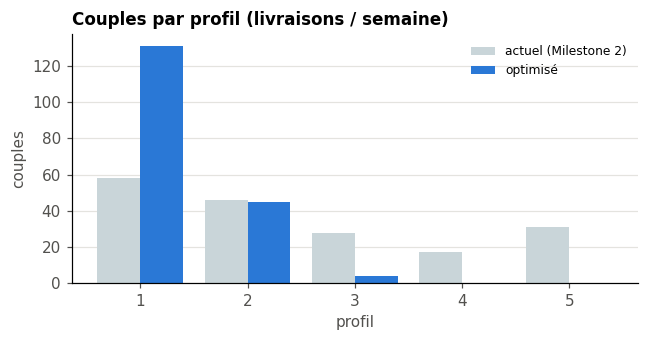

,actuel,optimisé
profile,,
1,58,131
2,46,45
3,28,4
4,17,0
5,31,0


In [7]:
best_cost = curve.groupby(list(cfg.couple_key))["model_cost"].transform("min")
eligible = curve[curve["model_cost"] <= best_cost * (1 + cfg.profile_tolerance) + 1e-6]
chosen_n = eligible.groupby(list(cfg.couple_key))["n_max"].min()

couples = chosen_n.rename("n_max").reset_index()
couples["plan"] = [solutions[s, p][n] for s, p, n in couples[[*cfg.couple_key, "n_max"]].itertuples(index=False)]
couples["profile"] = couples["plan"].map(lambda sol: len(sol.weekdays))
couples["weekdays"] = couples["plan"].map(lambda sol: ", ".join(WEEKDAYS[d] for d in sol.weekdays))
cost_by_n = curve.pivot_table(index=list(cfg.couple_key), columns="n_max", values="model_cost")
cost_by_n.columns = [f"cost_N{n}" for n in cost_by_n.columns]
couples = couples.merge(cost_by_n.reset_index(), on=list(cfg.couple_key), validate="1:1")

current_profile = pd.read_csv(cfg.data_dir / "baseline_couples.csv").set_index(list(cfg.couple_key))["profile"]
compare = pd.DataFrame({
    "actuel": current_profile.value_counts(),
    "optimisé": couples["profile"].value_counts(),
}).reindex(list(cfg.frequencies)).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(6, 3.2))
pos = np.arange(len(compare))
ax.bar(pos - 0.2, compare["actuel"], width=0.4, color="#c9d5d9", label="actuel (Milestone 2)")
ax.bar(pos + 0.2, compare["optimisé"], width=0.4, color=PRIMARY, label="optimisé")
ax.set_xticks(pos, compare.index.astype(str))
ax.set_title("Couples par profil (livraisons / semaine)")
ax.set_xlabel("profil"); ax.set_ylabel("couples"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
compare

## 6. Passe 2 : lissage par usine (RG09)

Le profil $N$ de chaque couple est maintenant fixé. Pour chaque couple, on calcule le coût et les camions par jour de **chaque jeu de $N$ jours de la semaine** (modèle 1.1 résolu avec les jours imposés, puis chargement 1.2). Ensuite, pour chaque usine, le modèle 1.3 choisit un jeu de jours par couple :
1. il minimise le **pic de camions reçus sur un jour** par l'usine ;
2. avec un surcoût d'au plus `smoothing_tolerance` (1 %) par rapport à la première passe ;
3. à pic égal, il prend le coût le plus bas.

La mesure de charge est le **nombre de camions par jour et par usine** : c'est ce qui occupe les quais.

23:44:02 INFO    250 / 965 weekday sets priced (27 s, 12 workers)


23:44:10 INFO    500 / 965 weekday sets priced (35 s, 12 workers)


23:44:12 INFO    750 / 965 weekday sets priced (37 s, 12 workers)


23:44:12 INFO    965 / 965 weekday sets priced (37 s, 12 workers)


23:44:12 INFO    Smoothing PLT_001: peak 15 -> 8 trucks/day, cost 27670 -> 27695 EUR (+0.09 %), 22 couples moved


23:44:12 INFO    Smoothing PLT_002: peak 56 -> 19 trucks/day, cost 28508 -> 28776 EUR (+0.94 %), 30 couples moved


23:44:13 INFO    Smoothing PLT_003: peak 9 -> 6 trucks/day, cost 19233 -> 19383 EUR (+0.78 %), 13 couples moved


23:44:13 INFO    Smoothing PLT_004: peak 14 -> 8 trucks/day, cost 34231 -> 34475 EUR (+0.71 %), 20 couples moved


23:44:13 INFO    Smoothing in 40 s: 1145 weekday sets priced for 180 couples


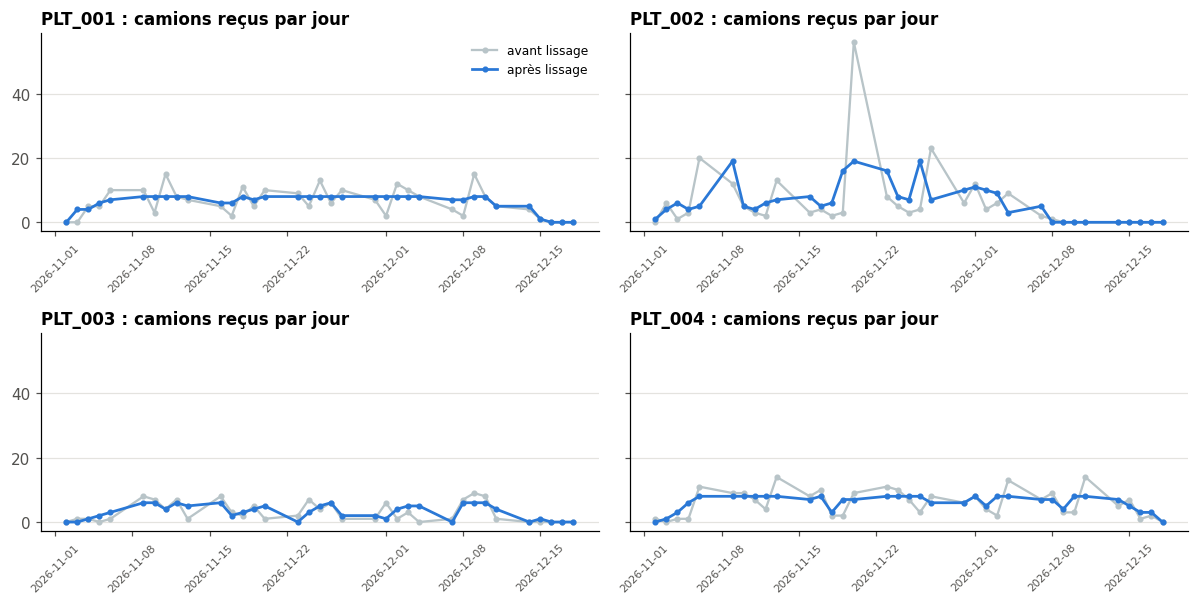

,couples,couples déplacés,pic avant (camions/jour),pic après (camions/jour),coût avant (EUR),coût après (EUR),surcoût (%),statut
usine,,,,,,,,
PLT_001,51,22,15,8,27 670.37,27 695.13,0.09,Optimal Solution Found
PLT_002,64,30,56,19,28 507.52,28 776.09,0.94,Optimal Solution Found
PLT_003,26,13,9,6,19 232.51,19 383.47,0.78,Optimal Solution Found
PLT_004,39,20,14,8,34 231.49,34 474.90,0.71,Optimal Solution Found


In [8]:
start = time.perf_counter()
first_pass = {(s, p): sol for s, p, sol in couples[[*cfg.couple_key, "plan"]].itertuples(index=False)}
options = build_options(instances, first_pass, CALENDAR, SETTINGS, workers=cfg.workers)
smoothing = {
    plant: smooth_plant(plant, {key: opts for key, opts in options.items() if key[1] == plant}, cfg.smoothing_tolerance)
    for plant in sorted({key[1] for key in options})
}
TIMINGS["passe 2 : options de jours et lissage des 4 usines"] = time.perf_counter() - start
smoothed: dict[tuple[str, str], CoupleOption] = {key: opt for res in smoothing.values() for key, opt in res.chosen.items()}
logger.info("Smoothing in %.0f s: %d weekday sets priced for %d couples", time.perf_counter() - start,
            sum(len(opts) for opts in options.values()), len(options))

couples["weekdays_first_pass"] = couples["weekdays"]
couples["plan"] = [smoothed[s, p].plan for s, p in couples[list(cfg.couple_key)].itertuples(index=False)]
couples["weekdays"] = couples["plan"].map(lambda sol: ", ".join(WEEKDAYS[d] for d in sol.weekdays))
couples["moved"] = couples["weekdays"] != couples["weekdays_first_pass"]
assert (couples["plan"].map(lambda sol: len(sol.weekdays)) == couples["profile"]).all(), "smoothing changed a profile"


def daily_trucks(choice: dict[tuple[str, str], CoupleOption]) -> pd.Series:
    """Trucks received by each plant on each day for one weekday set per couple."""
    rows = [{"plant": key[1], "day": pd.Timestamp(day), "trucks": int(n)}
            for key, opt in choice.items() for day, n in zip(opt.days, opt.trucks, strict=True)]
    return pd.DataFrame(rows).groupby(["plant", "day"])["trucks"].sum()


plant_load = pd.DataFrame({
    "avant lissage": daily_trucks({key: opts[0] for key, opts in options.items()}),
    "après lissage": daily_trucks(smoothed),
}).reindex(pd.MultiIndex.from_product([sorted(smoothing), DELIVERY_DAYS], names=["plant", "day"])).fillna(0).astype(int)
smoothing_summary = pd.DataFrame([{
    "usine": res.plant, "couples": len(res.chosen), "couples déplacés": int(couples.loc[couples["plant"] == res.plant, "moved"].sum()),
    "pic avant (camions/jour)": res.peak_before, "pic après (camions/jour)": res.peak_after,
    "coût avant (EUR)": res.cost_before, "coût après (EUR)": res.cost_after,
    "surcoût (%)": 100 * (res.cost_after / res.cost_before - 1), "statut": res.status,
} for res in smoothing.values()]).set_index("usine")

fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharey=True)
for ax, (plant, load) in zip(axes.flat, plant_load.groupby(level="plant"), strict=True):
    days = load.index.get_level_values("day")
    ax.plot(days, load["avant lissage"], color="#b8c4c8", lw=1.5, marker="o", ms=3, label="avant lissage")
    ax.plot(days, load["après lissage"], color=PRIMARY, lw=1.8, marker="o", ms=3, label="après lissage")
    ax.set_title(f"{plant} : camions reçus par jour")
    ax.tick_params(axis="x", labelsize=7, rotation=45)
axes.flat[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
smoothing_summary

## 7. Plan final et contrôles

Le plan lissé donne le jour de livraison de chaque ligne. Il est chargé camion par camion (modèle 1.2), puis contrôlé règle par règle :

| Règle | Contrôle |
| :--- | :--- |
| RG08 | chaque ligne est livrée, une seule fois |
| RG03 | anticipation entre 0 et 7 jours |
| RG10 | livraison un jour ouvré, hors jour férié |
| RG05 | livraison un jour autorisé du couple ; jamais plus de livraisons dans une semaine que le profil ; fréquence max atteinte = profil |
| RG09 | le lissage n'augmente le pic d'aucune usine |
| RG04 | aucun camion en surcharge, chaque ligne dans un camion (contrôlé dans `load_plan`) |

In [9]:
start = time.perf_counter()
chosen_plans = {(s, p): sol for s, p, sol in couples[[*cfg.couple_key, "plan"]].itertuples(index=False)}
plan = needs.assign(delivery_date=delivery_dates(chosen_plans))
plan["anticipation_days"] = (plan["date"] - plan["delivery_date"]).dt.days
trucks, plan["truck_no"] = load_plan(plan)
deliveries = build_deliveries(plan, trucks)
deliveries["week"] = deliveries["delivery_date"] - pd.to_timedelta(deliveries["delivery_date"].dt.dayofweek, unit="D")

TIMINGS["chargement du plan final"] = time.perf_counter() - start

# Rule checks on the final plan
per_week = deliveries.groupby([*cfg.couple_key, "week"]).size().rename("deliveries").reset_index()
per_week = per_week.merge(couples[[*cfg.couple_key, "profile"]], on=list(cfg.couple_key), validate="m:1")
assert plan["delivery_date"].notna().all() and len(plan) == len(needs), "RG08: a line is not delivered"
assert plan["anticipation_days"].between(0, cfg.max_anticipation_days).all(), "RG03: anticipation out of the window"
assert deliveries["delivery_date"].isin(DELIVERY_DAYS).all(), "RG10: delivery on a weekend or a holiday"
allowed_days = {(s, p): set(sol.weekdays) for s, p, sol in couples[[*cfg.couple_key, "plan"]].itertuples(index=False)}
on_allowed_day = [
    day.dayofweek in allowed_days[s, p]
    for s, p, day in deliveries[[*cfg.couple_key, "delivery_date"]].itertuples(index=False)
]
highest_frequency = per_week.groupby(list(cfg.couple_key)).agg(max_week=("deliveries", "max"), profile=("profile", "first"))
assert all(on_allowed_day), "RG05: delivery on a weekday that is not allowed by the profile"
assert (per_week["deliveries"] <= per_week["profile"]).all(), "RG05: more deliveries in a week than the profile"
assert (highest_frequency["max_week"] == highest_frequency["profile"]).all(), "RG05: profile wider than the highest weekly frequency"
assert np.isclose(deliveries["weight"].sum(), needs["weight"].sum()), "weight lost"
loaded_peak = trucks.groupby(["plant", "delivery_date"]).size().groupby(level="plant").max()
assert all(loaded_peak[p] <= smoothing[p].peak_before for p in smoothing), "RG09: smoothing raised a peak"
logger.info("Final plan: %.0f EUR vs current %.0f EUR (-%.1f %%) | %d trucks, %d deliveries need more than one truck",
            deliveries["cost"].sum(), BASELINE_COST, 100 * (1 - deliveries["cost"].sum() / BASELINE_COST),
            len(trucks), (deliveries["trucks"] > 1).sum())
pd.Series({
    "lignes livrées": len(plan), "anticipation max (jours)": int(plan["anticipation_days"].max()),
    "livraisons": len(deliveries), "camions": len(trucks),
    "livraisons un jour non autorisé": int(len(on_allowed_day) - sum(on_allowed_day)),
    "couples dont le profil dépasse la fréquence atteinte": int((highest_frequency["max_week"] != highest_frequency["profile"]).sum()),
}, name="plan final").to_frame()

23:44:15 INFO    Final plan: 110330 EUR vs current 176725 EUR (-37.6 %) | 761 trucks, 54 deliveries need more than one truck


,plan final
lignes livrées,4389
anticipation max (jours),7
livraisons,654
camions,761
livraisons un jour non autorisé,0
couples dont le profil dépasse la fréquence atteinte,0


## 8. Sortie 1 : le profil à appliquer pour chaque couple

Une ligne par couple fournisseur × usine (180 couples), au format de la présentation du projet :
- **livraisons / sem. actuelles :** le profil actuel, c'est-à-dire le nombre maximum de livraisons sur une semaine (Milestone 2) ;
- **fréquence cible et jours :** le profil retenu et ses jours autorisés, après lissage ;
- **camions / sem. :** nombre moyen de camions par semaine livrée ;
- **remplissage poids :** remplissage moyen des camions du couple.

Le tableau complet est exporté dans `optimized_profiles.csv`. Ci-dessous, les 15 couples au plus gros saving.

In [10]:
trucks_week = trucks.assign(week=trucks["delivery_date"] - pd.to_timedelta(trucks["delivery_date"].dt.dayofweek, unit="D"))
per_couple = trucks_week.groupby(list(cfg.couple_key)).agg(
    trucks=("truck_no", "size"), weeks=("week", "nunique"), fill_weight=("fill_weight", "mean"))
profiles_out = (
    couples[[*cfg.couple_key, "profile", "weekdays"]]
    .merge(INSTANCES_DISTANCE, on=list(cfg.couple_key), validate="1:1")
    .merge(current_profile.rename("current_per_week").reset_index(), on=list(cfg.couple_key), validate="1:1")
    .merge(per_couple.reset_index(), on=list(cfg.couple_key), validate="1:1")
    .merge(baseline_deliveries.groupby(list(cfg.couple_key))["cost"].sum().rename("baseline_cost").reset_index(),
           on=list(cfg.couple_key), validate="1:1")
    .merge(deliveries.groupby(list(cfg.couple_key))["cost"].sum().rename("optimised_cost").reset_index(),
           on=list(cfg.couple_key), validate="1:1")
)
profiles_out["trucks_per_week"] = profiles_out["trucks"] / profiles_out["weeks"]
profiles_out["saving"] = profiles_out["baseline_cost"] - profiles_out["optimised_cost"]
profiles_out = profiles_out.sort_values("saving", ascending=False, ignore_index=True)
assert len(profiles_out) == len(couples), "Output 1: a couple is missing"

output1 = pd.DataFrame({
    "fournisseur": profiles_out["supplier_id"], "usine": profiles_out["plant"],
    "distance (km)": profiles_out["distance"].round(0).astype(int),
    "livraisons / sem. actuelles": profiles_out["current_per_week"],
    "fréquence cible": profiles_out["profile"].map(lambda n: f"{n} / semaine"),
    "jours": profiles_out["weekdays"],
    "camions / sem.": profiles_out["trucks_per_week"].round(1),
    "remplissage poids (%)": (100 * profiles_out["fill_weight"]).round(1),
    "coût actuel (EUR)": profiles_out["baseline_cost"], "coût optimisé (EUR)": profiles_out["optimised_cost"],
})
logger.info("Output 1: %d couples | target frequency %s", len(output1),
            profiles_out["profile"].value_counts().sort_index().to_dict())
output1.head(15)

23:44:15 INFO    Output 1: 180 couples | target frequency {1: 131, 2: 45, 3: 4}


,fournisseur,usine,distance (km),livraisons / sem. actuelles,fréquence cible,jours,camions / sem.,remplissage poids (%),coût actuel (EUR),coût optimisé (EUR)
0,SUP_00085,PLT_004,121,5,1 / semaine,lundi,1.00,48.20,7 429.18,1 988.44
1,SUP_00146,PLT_002,122,5,2 / semaine,"lundi, mardi",1.20,42.70,4 651.48,1 151.09
2,SUP_00059,PLT_003,122,5,1 / semaine,mercredi,1.00,19.00,3 874.58,1 587.59
3,SUP_00144,PLT_001,38,5,2 / semaine,"lundi, mercredi",1.20,63.90,3 454.61,1 283.49
4,SUP_00080,PLT_004,40,5,1 / semaine,vendredi,1.00,18.80,2 989.46,1 179.94
5,SUP_00118,PLT_001,100,5,1 / semaine,vendredi,1.00,13.10,3 210.51,1 451.38
6,SUP_00129,PLT_003,84,5,3 / semaine,"lundi, mercredi, vendredi",6.00,82.50,10 143.87,8 477.40
7,SUP_00145,PLT_004,67,5,2 / semaine,"mardi, vendredi",1.20,13.70,3 033.99,1 427.68
8,SUP_00087,PLT_004,98,5,1 / semaine,lundi,1.00,11.20,2 995.95,1 404.51
9,SUP_00011,PLT_004,145,5,1 / semaine,lundi,1.00,6.20,2 861.52,1 282.64


## 9. Sortie 2 : les articles regroupés dans chaque camion

Pour chaque camion (couple + jour + n°), la liste des articles qu'il transporte : quai, jours de besoin regroupés, quantité, poids et volume. Une ligne du tableau = un article × un quai dans un camion.
- Le fichier complet est exporté dans `optimized_truck_materials.csv` (section 11).
- Ci-dessous, l'exemple de la présentation : le camion de SUP_00085 × PLT_004 la semaine du 16/11.
- « Remplace » = nombre de livraisons actuelles (couple × jour de besoin) dont les lignes partent dans ce camion.

In [11]:
def truck_materials(plan: pd.DataFrame) -> pd.DataFrame:
    """Output 2: one row per truck x material x unloading point, with the days of need it groups."""
    keys = [*cfg.couple_key, "delivery_date", "truck_no", "material", "unloading_point"]
    content = (
        plan.groupby(keys)
        .agg(need_days=("date", lambda days: ", ".join(f"{d:%d/%m}" for d in sorted(set(days)))),
             lines=("line_id", "size"), quantity=("schedule_quantity", "sum"),
             weight=("weight", "sum"), volume=("volume", "sum"))
        .reset_index()
    )
    order = [*cfg.couple_key, "delivery_date", "truck_no", "weight"]
    return content.sort_values(order, ascending=[True] * (len(order) - 1) + [False], ignore_index=True)


truck_content = truck_materials(plan)
assert np.isclose(truck_content["weight"].sum(), needs["weight"].sum()), "Output 2: weight lost"
assert truck_content["lines"].sum() == len(needs), "Output 2: a line is missing"

# Example of the presentation: the heaviest truck of SUP_00085 x PLT_004 in the week of 16/11/2026
EXAMPLE_COUPLE, EXAMPLE_WEEK = ("SUP_00085", "PLT_004"), pd.Timestamp("2026-11-16")
week_trucks = trucks[(trucks["supplier_id"] == EXAMPLE_COUPLE[0]) & (trucks["plant"] == EXAMPLE_COUPLE[1])
                     & trucks["delivery_date"].between(EXAMPLE_WEEK, EXAMPLE_WEEK + pd.Timedelta(days=4))]
assert not week_trucks.empty, "the example couple has no truck in the example week"
truck = week_trucks.loc[week_trucks["weight"].idxmax()]


def is_example_truck(frame: pd.DataFrame) -> pd.Series:
    """Rows of a frame that belong to the example truck."""
    return ((frame["supplier_id"] == truck["supplier_id"]) & (frame["plant"] == truck["plant"])
            & (frame["delivery_date"] == truck["delivery_date"]) & (frame["truck_no"] == truck["truck_no"]))


in_truck = plan[is_example_truck(plan)]
example = truck_content[is_example_truck(truck_content)]

logger.info("Output 2 example: %s x %s, truck %d of %s | %d materials, %d lines | %.1f t (%.1f %%), %.1f m3 (%.1f %%) "
            "| %.0f EUR | replaces %d current deliveries", truck["supplier_id"], truck["plant"], truck["truck_no"],
            truck["delivery_date"].date(), len(example), len(in_truck), truck["weight"] / 1000,
            100 * truck["fill_weight"], truck["volume"], 100 * truck["fill_volume"], truck["cost"],
            in_truck["date"].nunique())
shown = example[["material", "unloading_point", "need_days", "lines", "quantity", "weight", "volume"]].rename(columns={
    "material": "article", "unloading_point": "quai", "need_days": "besoins regroupés", "lines": "lignes",
    "quantity": "quantité", "weight": "poids (kg)", "volume": "volume (m³)",
})
total = pd.DataFrame([{"article": "Total camion", "quai": "", "besoins regroupés": f"{len(in_truck)} lignes de besoin",
                       "lignes": shown["lignes"].sum(), "quantité": shown["quantité"].sum(),
                       "poids (kg)": shown["poids (kg)"].sum(), "volume (m³)": shown["volume (m³)"].sum()}])
pd.concat([shown, total], ignore_index=True)

23:44:15 INFO    Output 2 example: SUP_00085 x PLT_004, truck 1 of 2026-11-16 | 16 materials, 31 lines | 9.7 t (39.7 %), 28.0 m3 (25.4 %) | 331 EUR | replaces 5 current deliveries


,article,quai,besoins regroupés,lignes,quantité,poids (kg),volume (m³)
0,MAT_000298,ULP_0010,"17/11, 18/11, 19/11, 20/11",4,1 014.00,3 254.10,3.16
1,MAT_000074,ULP_0050,"17/11, 18/11, 19/11, 20/11",4,1 200.00,1 100.40,4.80
2,MAT_000455,ULP_0050,"17/11, 18/11, 20/11",3,1 350.00,977.10,2.67
3,MAT_000131,ULP_0010,"17/11, 20/11",2,240.00,697.60,1.58
4,MAT_000966,ULP_0050,"17/11, 20/11",2,1 200.00,526.80,2.40
5,MAT_000103,ULP_0050,19/11,1,750.00,468.50,1.20
6,MAT_000621,ULP_0050,17/11,1,450.00,385.10,1.20
7,MAT_000505,ULP_0050,20/11,1,4 000.00,337.60,1.20
8,MAT_000808,ULP_0050,19/11,1,1 000.00,331.40,0.57
9,MAT_000270,ULP_0050,"16/11, 17/11, 19/11",3,870.00,304.80,1.71


## 10. Sortie 3 : le saving

### 10.1 Avant optimisation, après optimisation, après lissage

Trois états du plan, tous chargés camion par camion :
- **actuel :** chaque ligne livrée le jour de son besoin (Milestone 2) ;
- **après optimisation :** plan de la passe 1 (profils choisis, jours non lissés) ;
- **après lissage :** plan final, après la passe 2 (section 6).

Les graphiques comparent le coût, le nombre de livraisons et de camions, le coût et le pic de camions par usine, puis la répartition des camions sur les jours de la semaine.

La dernière figure reprend la heatmap du Milestone 1 : le nombre de livraisons dans chaque case de la grille tarifaire (tranche de distance × tranche de poids de la livraison), avant et après. La consolidation déplace les livraisons des petites tranches de poids, les plus chères au kilo, vers les tranches lourdes et le forfait (> 4 000 kg).

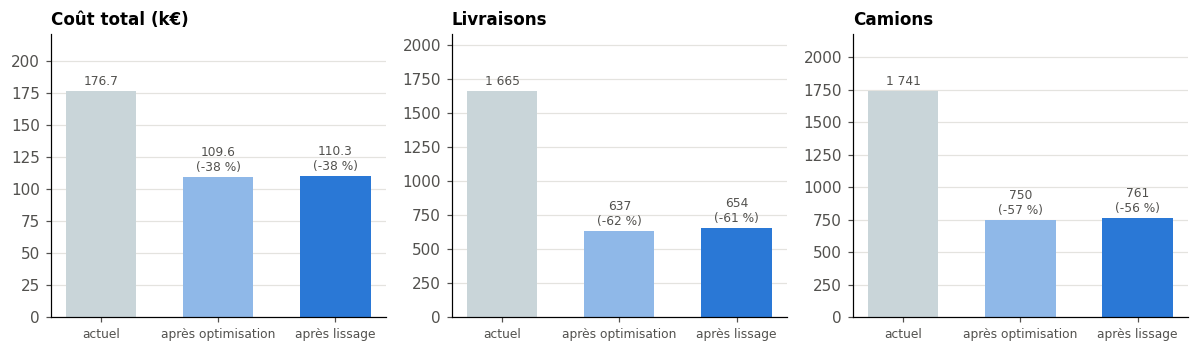

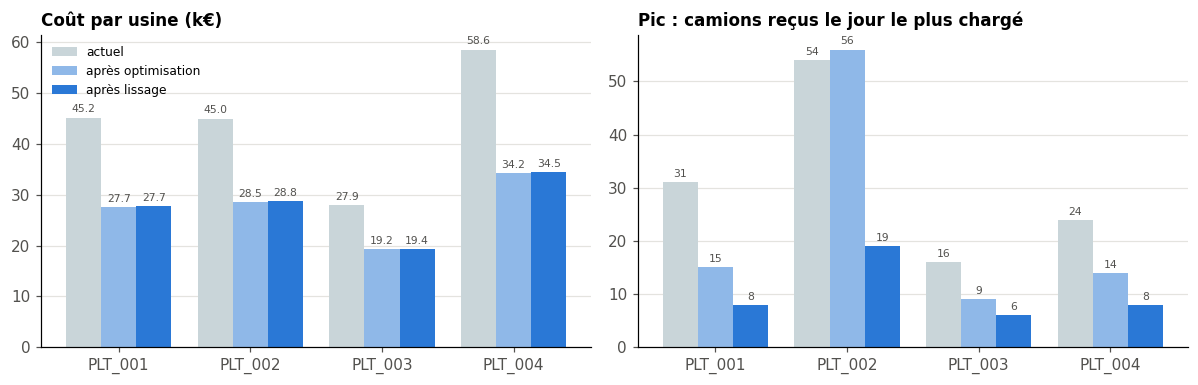

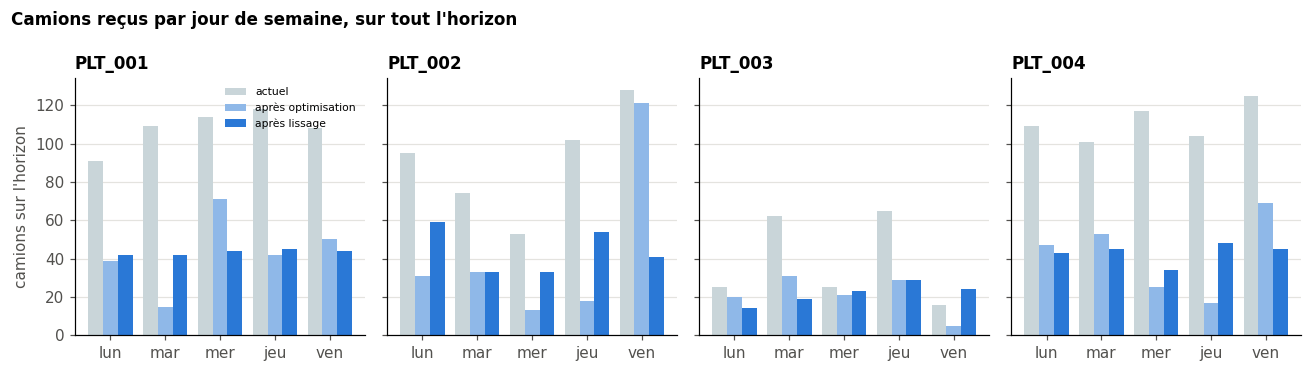

,coût total (EUR),livraisons,camions,pic max d'une usine (camions/jour)
actuel,176 724.61,1665,1741,54
après optimisation,109 641.90,637,750,56
après lissage,110 329.59,654,761,19


In [12]:
STATES = ["actuel", "après optimisation", "après lissage"]
STATE_COLORS = ["#c9d5d9", "#8fb8e8", PRIMARY]
first_pass_choice = {key: opts[0] for key, opts in options.items()}  # option 0 = plan of the first pass
plants = sorted(smoothing)

daily_by_state = {  # trucks received per plant and per day
    "actuel": baseline_trucks.groupby(["plant", "delivery_date"]).size(),
    "après optimisation": daily_trucks(first_pass_choice).rename_axis(["plant", "delivery_date"]),
    "après lissage": trucks.groupby(["plant", "delivery_date"]).size(),
}
plant_cost = pd.DataFrame({
    "actuel": baseline_deliveries.groupby("plant")["cost"].sum(),
    "après optimisation": pd.Series({p: sum(o.cost for k, o in first_pass_choice.items() if k[1] == p) for p in plants}),
    "après lissage": deliveries.groupby("plant")["cost"].sum(),
})[STATES]
states = pd.DataFrame({
    "coût total (EUR)": plant_cost.sum(),
    "livraisons": pd.Series([len(baseline_deliveries), sum(len(o.days) for o in first_pass_choice.values()),
                             len(deliveries)], index=STATES),
    "camions": pd.Series({s: int(d.sum()) for s, d in daily_by_state.items()}),
    "pic max d'une usine (camions/jour)": pd.Series({s: int(d.max()) for s, d in daily_by_state.items()}),
})
peaks = pd.DataFrame({s: d.groupby(level="plant").max() for s, d in daily_by_state.items()})[STATES]
assert np.isclose(states.loc["après lissage", "coût total (EUR)"], deliveries["cost"].sum()), "state costs mismatch"


def grouped_bars(ax: plt.Axes, table: pd.DataFrame, fmt: str = "{:,.0f}") -> None:
    """Grouped bars: one group per row of the table, one bar per state (column)."""
    pos = np.arange(len(table))
    width = 0.8 / len(table.columns)
    for i, (state, color) in enumerate(zip(table.columns, STATE_COLORS, strict=True)):
        bars = ax.bar(pos + (i - 1) * width, table[state], width=width, color=color, label=state)
        ax.bar_label(bars, labels=[fmt.format(v).replace(",", " ") for v in table[state]], padding=2, fontsize=7,
                     color=MUTED)
    ax.set_xticks(pos, table.index)


# 1. Totals
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (column, title, scale) in zip(axes, [("coût total (EUR)", "Coût total (k€)", 1000),
                                             ("livraisons", "Livraisons", 1), ("camions", "Camions", 1)], strict=True):
    values = states[column] / scale
    bars = ax.bar(STATES, values, color=STATE_COLORS, width=0.6)
    labels = [f"{v:,.1f}".replace(",", " ") if scale > 1 else f"{v:,.0f}".replace(",", " ") for v in values]
    labels = [lab if s == "actuel" else f"{lab}\n({100 * (v / values.iloc[0] - 1):+.0f} %)"
              for lab, s, v in zip(labels, STATES, values, strict=True)]
    ax.bar_label(bars, labels=labels, padding=2, fontsize=8, color=MUTED)
    ax.set_title(title); ax.set_ylim(0, values.max() * 1.25); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

# 2. Per plant: cost and daily truck peak
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
grouped_bars(axes[0], plant_cost / 1000, "{:,.1f}")
axes[0].set_title("Coût par usine (k€)"); axes[0].legend(fontsize=8)
grouped_bars(axes[1], peaks)
axes[1].set_title("Pic : camions reçus le jour le plus chargé")
plt.tight_layout(); plt.show()

# 3. Trucks per weekday and per plant over the whole horizon
fig, axes = plt.subplots(1, len(plants), figsize=(12, 3.4), sharey=True)
for ax, plant in zip(axes, plants, strict=True):
    by_weekday = pd.DataFrame({
        s: d.loc[plant].groupby(d.loc[plant].index.dayofweek).sum() for s, d in daily_by_state.items()
    }).reindex(range(5), fill_value=0).fillna(0)[STATES]
    by_weekday.index = [WEEKDAYS[i][:3] for i in by_weekday.index]
    pos = np.arange(5)
    for i, (state, color) in enumerate(zip(STATES, STATE_COLORS, strict=True)):
        ax.bar(pos + (i - 1) * 0.27, by_weekday[state], width=0.27, color=color, label=state)
    ax.set_xticks(pos, by_weekday.index); ax.set_title(plant)
axes[0].legend(fontsize=7); axes[0].set_ylabel("camions sur l'horizon")
fig.suptitle("Camions reçus par jour de semaine, sur tout l'horizon", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
states

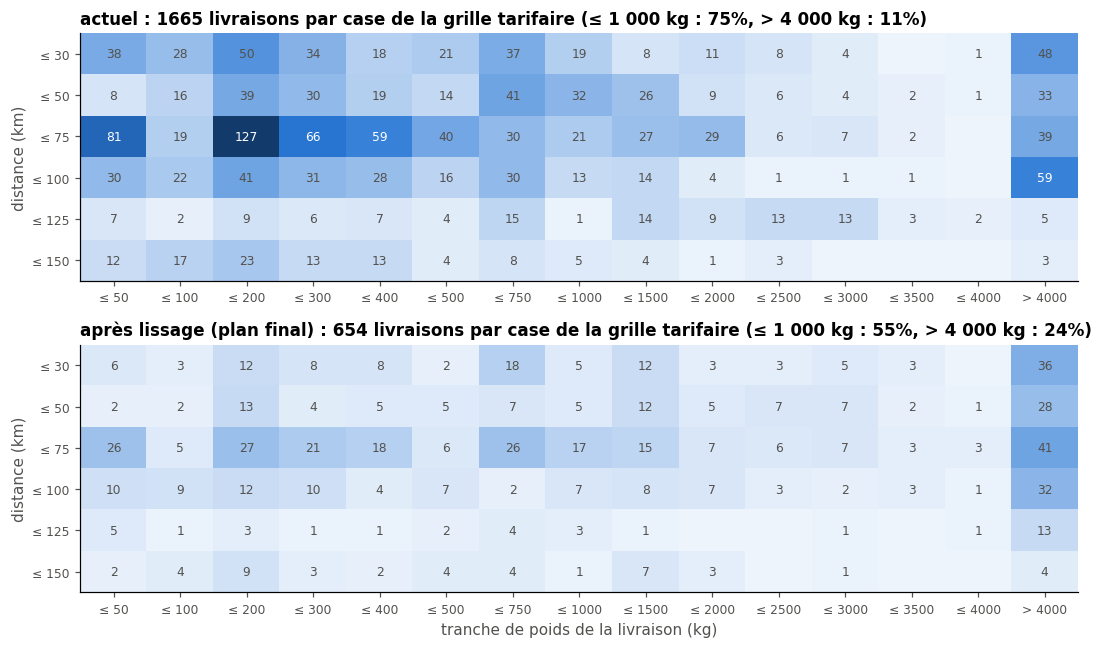

In [13]:
from matplotlib.colors import LinearSegmentedColormap

KG_LABELS = [f"≤ {c:g}" if np.isfinite(c) else "> 4000" for c in KG_BOUNDS]
KM_LABELS = [f"≤ {k:g}" if np.isfinite(k) else "> 650" for k in KM_BOUNDS]


def rate_sheet_cells(d: pd.DataFrame) -> pd.DataFrame:
    """Number of deliveries in each rate sheet cell (distance bracket x weight bracket of the delivery)."""
    km = bracket_index(d["distance"].to_numpy(dtype=float), KM_BOUNDS)
    kg = bracket_index(d["weight"].to_numpy(dtype=float), KG_BOUNDS)
    return pd.crosstab(pd.Series(km, name="km"), pd.Series(kg, name="kg")).reindex(
        index=range(len(KM_BOUNDS)), columns=range(len(KG_BOUNDS)), fill_value=0)


heat = {"actuel": rate_sheet_cells(baseline_deliveries), "après lissage (plan final)": rate_sheet_cells(deliveries)}
used_rows = sorted(set().union(*(m.index[m.sum(axis=1) > 0] for m in heat.values())))  # distance brackets with data
vmax = max(int(m.values.max()) for m in heat.values())  # same colour scale for both maps
cmap = LinearSegmentedColormap.from_list("seq", ["#eef4fc", PRIMARY, "#123a6b"])

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, (state, mat) in zip(axes, heat.items(), strict=True):
    values = mat.loc[used_rows].to_numpy()
    ax.imshow(values, cmap=cmap, aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(KG_LABELS)), KG_LABELS, fontsize=8)
    ax.set_yticks(range(len(used_rows)), [KM_LABELS[r] for r in used_rows], fontsize=8)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if values[i, j]:
                ax.text(j, i, values[i, j], ha="center", va="center", fontsize=8,
                        color="white" if values[i, j] > vmax * 0.45 else MUTED)
    ax.grid(False)
    ax.set_ylabel("distance (km)")
    light = (baseline_deliveries if state == "actuel" else deliveries)["weight"]
    ax.set_title(f"{state} : {int(values.sum())} livraisons par case de la grille tarifaire "
                 f"(≤ 1 000 kg : {(light <= 1000).mean():.0%}, > 4 000 kg : {(light > 4000).mean():.0%})")
axes[-1].set_xlabel("tranche de poids de la livraison (kg)")
plt.tight_layout(); plt.show()

### 10.2 Indicateurs et saving par usine

Mêmes définitions qu'au Milestone 2, situation actuelle et plan final chargés de la même façon.

In [14]:
def kpis(d: pd.DataFrame) -> pd.Series:
    """Indicators of a set of deliveries (same definitions as milestone 2)."""
    return pd.Series({
        "livraisons": len(d),
        "camions": int(d["trucks"].sum()),
        "poids médian d'une livraison (kg)": d["weight"].median(),
        "remplissage médian (%)": 100 * d["fill"].median(),
        "coût total (EUR)": d["cost"].sum(),
    })


comparison = pd.DataFrame({"actuel": kpis(baseline_deliveries), "optimisé": kpis(deliveries)})
comparison["écart (%)"] = 100 * (comparison["optimisé"] / comparison["actuel"] - 1)
by_plant = pd.DataFrame({
    "coût actuel (EUR)": baseline_deliveries.groupby("plant")["cost"].sum(),
    "coût optimisé (EUR)": deliveries.groupby("plant")["cost"].sum(),
})
by_plant["saving (%)"] = 100 * (1 - by_plant["coût optimisé (EUR)"] / by_plant["coût actuel (EUR)"])
display(by_plant)
comparison

,coût actuel (EUR),coût optimisé (EUR),saving (%)
plant,,,
PLT_001,45 200.68,27 695.13,38.73
PLT_002,45 004.43,28 776.09,36.06
PLT_003,27 931.81,19 383.47,30.60
PLT_004,58 587.68,34 474.90,41.16


,actuel,optimisé,écart (%)
livraisons,1 665.00,654.00,-60.72
camions,1 741.00,761.00,-56.29
poids médian d'une livraison (kg),349.64,828.14,136.86
remplissage médian (%),1.61,3.65,127.00
coût total (EUR),176 724.61,110 329.59,-37.57


## 11. Export

| Fichier | Une ligne = | Usage |
| :--- | :--- | :--- |
| `optimized_lines.csv` | une ligne de besoin, avec son jour de livraison, son anticipation et son camion (`truck_no`) | plan détaillé (Sortie 2) |
| `optimized_trucks.csv` | un camion (couple + jour + n°), avec lignes, articles, quais, poids, volume, remplissage et coût | camions (Sortie 2) |
| `optimized_truck_materials.csv` | un article × un quai dans un camion, avec les jours de besoin regroupés, la quantité, le poids et le volume | articles regroupés dans chaque camion (Sortie 2) |
| `optimized_deliveries.csv` | une livraison (couple × jour), avec charge, camions et coût | camions et coûts (Sortie 2, 3) |
| `optimized_profiles.csv` | un couple : profil actuel, fréquence cible, jours, camions par semaine, remplissage, coût actuel et optimisé | profils (Sortie 1) |
| `optimized_couples.csv` | un couple : profil, jours de livraison après lissage (et avant : `weekdays_first_pass`), coût pour chaque $N$ | profils (Sortie 1), règle RG07 modifiable |
| `optimized_plant_load.csv` | une usine × un jour : camions reçus avant et après lissage | lissage (RG09) |
| `optimized_kpis.csv` | un indicateur, actuel et optimisé | économie (Sortie 3) |

In [15]:
cfg.output_dir.mkdir(parents=True, exist_ok=True)
baseline_cost = baseline_deliveries.groupby(list(cfg.couple_key))["cost"].sum().rename("baseline_cost")
optimised_cost = deliveries.groupby(list(cfg.couple_key))["cost"].sum().rename("optimised_cost")
couples_out = (couples.drop(columns="plan")
               .merge(baseline_cost.reset_index(), on=list(cfg.couple_key), validate="1:1")
               .merge(optimised_cost.reset_index(), on=list(cfg.couple_key), validate="1:1"))
couples_out["saving"] = couples_out["baseline_cost"] - couples_out["optimised_cost"]

plan.to_csv(cfg.output_dir / "optimized_lines.csv", index=False, date_format="%Y-%m-%d")
deliveries.to_csv(cfg.output_dir / "optimized_deliveries.csv", index=False, date_format="%Y-%m-%d")
trucks.to_csv(cfg.output_dir / "optimized_trucks.csv", index=False, date_format="%Y-%m-%d")
truck_content.to_csv(cfg.output_dir / "optimized_truck_materials.csv", index=False, date_format="%Y-%m-%d")
couples_out.to_csv(cfg.output_dir / "optimized_couples.csv", index=False)
comparison.to_csv(cfg.output_dir / "optimized_kpis.csv", index_label="indicator")
profiles_out.to_csv(cfg.output_dir / "optimized_profiles.csv", index=False)
plant_load.to_csv(cfg.output_dir / "optimized_plant_load.csv", date_format="%Y-%m-%d")
logger.info("Files written to %s", cfg.output_dir.resolve().name)

23:44:16 INFO    Files written to data


## Annexes

### A.1 Biais de l'estimateur du Milestone 2

L'estimateur du Milestone 2 traitait le poids et le volume d'une livraison comme divisibles. Ce tableau le compare au chargement camion par camion (modèle 1.2), pour la situation actuelle et pour le plan final.

In [16]:
bias = pd.DataFrame({
    "estimateur Milestone 2 (EUR)": [baseline_deliveries["estimator_cost"].sum(), deliveries["estimator_cost"].sum()],
    "chargement camion par camion (EUR)": [BASELINE_COST, deliveries["cost"].sum()],
    "camions (chargement)": [len(baseline_trucks), len(trucks)],
}, index=["actuel", "optimisé"])
bias["écart (%)"] = 100 * (bias.iloc[:, 1] / bias.iloc[:, 0] - 1)
bias

,estimateur Milestone 2 (EUR),chargement camion par camion (EUR),camions (chargement),écart (%)
actuel,176 979.32,176 724.61,1741,-0.14
optimisé,110 605.82,110 329.59,761,-0.25


### A.2 Statistiques du solveur et anticipation

Nombre de résolutions et temps par statut (« Optimal Solution Found » = écart ≤ `mip_gap` ; « Solution Found » = arrêt sur la limite de temps avec une bonne solution), puis nombre de lignes par jour d'anticipation dans le plan final.

In [17]:
solve_stats = curve[curve["seconds"] > 0].groupby("status").agg(solves=("seconds", "size"), seconds=("seconds", "sum"))
display(solve_stats)
plan["anticipation_days"].value_counts().sort_index().rename_axis("anticipation (jours)").rename("lignes").to_frame().T

,solves,seconds
status,,
Optimal Solution Found,214,163.14
Solution Found,26,130.81


anticipation (jours),0,1,2,3,4,5,6,7
lignes,849,535,401,476,434,372,500,822


### A.3 Temps d'exécution

Durée de chaque étape de cette exécution, avec le parallélisme (un processus par cœur du processeur, ou `workers` s'il est fixé). Le temps dépend de la machine et de sa charge : avec d'autres applications actives, la passe 1 peut prendre nettement plus longtemps.

La dernière ligne donne un ordre de grandeur sans parallélisme : la somme des temps de résolution enregistrés pour les plans retenus. C'est une borne basse, car les problèmes dont le plan a été remplacé par celui d'un autre profil ne sont pas comptés.

In [18]:
workers_used = cfg.workers or os.cpu_count() or 1
timings = pd.Series(TIMINGS, name="durée (s)").to_frame()
timings.loc["total du notebook"] = time.perf_counter() - NOTEBOOK_START
timings.loc["passe 1 sans parallélisme (somme des résolutions retenues, borne basse)"] = curve["seconds"].sum()
timings["durée (min)"] = timings["durée (s)"] / 60
logger.info("Notebook run in %.0f s with %d parallel workers", timings.loc["total du notebook", "durée (s)"], workers_used)
timings.round(1)

23:44:16 INFO    Notebook run in 151 s with 12 parallel workers


,durée (s),durée (min)
données et calendrier,0.30,0.00
"validation (fenêtre de 0 jour, situation actuelle rechargée)",3.20,0.10
passe 1 : 900 problèmes (couple × profil),105.40,1.80
passe 2 : options de jours et lissage des 4 usines,39.70,0.70
chargement du plan final,1.10,0.00
total du notebook,151.20,2.50
"passe 1 sans parallélisme (somme des résolutions retenues, borne basse)",294.00,4.90


### A.4 Coût total si tous les couples avaient le même profil

Coût du modèle 1.1 (avant chargement), pour chaque profil $N$ imposé à tous les couples, comparé à la situation actuelle.

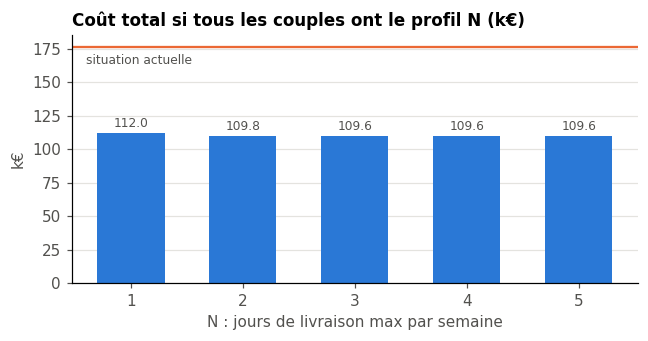

In [19]:
total_by_n = curve.groupby("n_max")["model_cost"].sum()  # model cost, before loading
fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(total_by_n.index.astype(str), total_by_n / 1000, color=PRIMARY, width=0.6)
ax.bar_label(bars, labels=[f"{v / 1000:,.1f}".replace(",", " ") for v in total_by_n], padding=2, fontsize=8, color=MUTED)
ax.axhline(BASELINE_COST / 1000, color=ACCENT, lw=1.5)
ax.text(-0.4, BASELINE_COST / 1000 * 0.97, "situation actuelle", va="top", fontsize=8, color=MUTED)
ax.set_title("Coût total si tous les couples ont le profil N (k€)")
ax.set_xlabel("N : jours de livraison max par semaine"); ax.set_ylabel("k€")
plt.tight_layout(); plt.show()